# Spikecurate

_via regression model_

**author**: laquitainesteeve@gmail.com

**purpose**: show the weights of the best logistic regression that curates the "good" units (>80% agreement score) amongst the sorted single-units, for the first 10 min of the biophysical simulation in the spontaneous regime (fig5g). The weights are in percentile-rank units; their uncertainty (bootstrap) and significance (permutation test) are computed on the units. The paper's version of this panel (generalised linear model on z-scored metrics) is in fig5g_paper_model.ipynb.

**tested on**:

* Ubuntu 24.04.1 LTS (32 cores, 188 GB RAM, Intel(R) Core(TM) i9-14900K ＠3.2 GHz/5.8 GHz) with RTX 5090 GPU with 40GB VRAM (GPU not needed)

**Method**
- kilosort4's sorting extractor was generated with rtx5090 GPU, so the results slightly change from the original Tesla V100
- a dataset dataframe that contains the sorted single-units (indices), their quality metrics and their quality label ("good" or "bad" units evaluated with our ground truth, columns)

**Execution time**: 3 min


## Setup 

1. Create and activate envs/spikebias.yml

In [22]:
# automatically reload notebook
%load_ext autoreload
%autoreload 2

# import built-in packages
import os

# limit BLAS/OpenMP threads per worker, BEFORE numpy is imported (restart the kernel
# if numpy was already imported): the PCA runs ~20x faster than with default threads
# Each worker runs many small PCA fits, each fit makes many BLAS/LAPACK calls, by 
# default each call can use up to 32 threads. We capped that to 1 thread, which 
# substantially removed overhead and sped up compute.
# 2 min instead of 1.5h
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
    
import shutil
import pickle
import copy
import random
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.core.template_tools as ttools
from spikeinterface import comparison
from spikeinterface.curation import remove_excess_spikes
from spikeinterface import extract_waveforms
from spikeinterface.postprocessing import compute_principal_components
from spikeinterface.qualitymetrics import compute_quality_metrics as qm
import statsmodels.api as sm
from statsmodels.tools.validation import float_like
import torch
import numpy as np
from matplotlib import pyplot as plt
import sklearn
import seaborn as sns
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
import warnings
import spikecurate 

# silence irrelevant warnings
warnings.filterwarnings("ignore", message="There is no Probe attached to this recording.*")
warnings.filterwarnings("ignore", message="Versions are not the same.*")

# spikeinterface version
print("Spikeinterface", si.__version__)

# set project path
proj_path = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(proj_path)
os.environ["PYTHONPATH"] = proj_path     # worker processes (joblib) must be able to import the project

# import custom package
# (helpers that read sorting_quality.csv are not in the spikecurate package)
from src.nodes.models.Flc import dataloader
from src.nodes.models.Flc import extra_features as ef             # candidate features
from src.nodes.models.Flc import curation_models as cm           # curation models + nested cross-validation

# experiment parameters
EXP = "NS"
SORTER = "KS4"

# waveform extraction parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 6
MS_AFTER = 6
LOAD_WE = False
DURATION_SEC = 600          # 10 minutes recording
MAX_SPIKES_PER_UNIT = 500   # max number of spikes used per unit
SEED = 0
N_COMP_PCA = 5              # number of pca components
SPARSE = True
OVERWRITE = True
WE_JOB_KWARGS = dict(n_jobs=20, chunk_duration="1s", progress_bar=True)
job_kwargs = dict(n_jobs=-1, progress_bar=True)

CHUNKS = 80000 # for waveform extractor

# model parameters
model_prms = {"seeds": np.arange(0,100,1), "scale_data": False}

# recording extractor
RECORDING_PATH = "dataset/00_raw/recording_npx_spont/"

# kilosort sorting extractor
SORTING_KS4_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m/"

# ground truth extractors
SORTING_TRUE = "dataset/00_raw/ground_truth_npx_spont"
SORTING_TRUE_10mn = "dataset/00_raw/ground_truth_npx_spont_10m"

# waveform extractors
# WE_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m/"
WE_SINGLE_U_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m_single_units"

# unit classification
QUALITY_PATH = "dataset/01_intermediate/analysis/sorting_quality/sorting_quality.csv"

# figure parameters
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5 # typically between 0.5 and 1
plt.rcParams["axes.linewidth"] = 0.5 
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# figure legend parameters
legend_cfg = {"frameon": False, "handletextpad": 0.5}
tight_layout_cfg = {"pad": 0.001}
LG_FRAMEON = False              # no legend frame

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Spikeinterface 0.100.8


## Load datasets

* Execution time: 27 ms

### Recording extractor

* Execution time: 

In [23]:
%%time

# load and preprocess recording
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property('location', Recording.get_property('location')[:,:2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
# keep the first 10 min so that the recording duration matches the sorting
# (duration-dependent quality metrics: firing_rate, firing_range, presence_ratio)
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
display(Recording)

FrameSliceRecording: 384 channels - 40.0kHz - 1 segments - 24,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 34.33 GiB

CPU times: user 3.17 ms, sys: 134 µs, total: 3.31 ms
Wall time: 3.16 ms


### Ground truth extractor

* Execution time: 

In [24]:
%%time

# load ground truth
SortingTrue = si.load_extractor(SORTING_TRUE)
SortingTrue = SortingTrue.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
SortingTrue.save(folder=SORTING_TRUE_10mn, overwrite=True)
display(SortingTrue)

FrameSliceSorting: 1388 units - 1 segments - 40.0kHz

CPU times: user 250 ms, sys: 4.14 ms, total: 254 ms
Wall time: 254 ms


### Sorting extractor

* Execution time: 20 ms

In [25]:
%%time

# load sorting
Sorting = si.load_extractor(SORTING_KS4_PATH)
Sorting = remove_excess_spikes(Sorting, Recording)
Sorting = Sorting.frame_slice(start_frame=0, end_frame=Recording.get_sampling_frequency() * DURATION_SEC)
display(Sorting)

FrameSliceSorting: 520 units - 1 segments - 40.0kHz

CPU times: user 1.92 ms, sys: 0 ns, total: 1.92 ms
Wall time: 1.83 ms


### Waveform extractor (Sorted units)

* Execution time: 2.5 min

In [26]:
%%time 

# select sorted single-units amongst single- and multi-units (KSLABEL="good" for kilosort4)
single_unit_ids = Sorting.unit_ids[np.where(Sorting.get_property("KSLabel") == "good")[0]]
Sorting_single_units = Sorting.select_units(unit_ids=single_unit_ids)

# save their waveforms
We_single_u = extract_waveforms(Recording, Sorting_single_units, WE_SINGLE_U_PATH, mode="folder", sparse=SPARSE, ms_before=MS_BEFORE,
                    ms_after=MS_AFTER, max_spikes_per_unit=MAX_SPIKES_PER_UNIT, unit_batch_size=CHUNKS,
                    overwrite=OVERWRITE, seed=SEED, **WE_JOB_KWARGS)


# save waveform PCA data (the extractor is updated)
pca = compute_principal_components(waveform_extractor=We_single_u, n_components=N_COMP_PCA, mode="by_channel_local", **WE_JOB_KWARGS)

extract waveforms shared_memory multi buffer:   0%|          | 0/600 [00:00<?, ?it/s]

extract waveforms memmap multi buffer:   0%|          | 0/600 [00:00<?, ?it/s]

Fitting PCA:   0%|          | 0/184 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/184 [00:00<?, ?it/s]

CPU times: user 25.1 s, sys: 1min 56s, total: 2min 21s
Wall time: 3min 37s


### Single-unit ids and labels (good/gad)

In [27]:
%%time

# label "good" and "bad" sorted single-units to train the classifier
good_unit_ids, bad_unit_ids = dataloader.get_good_and_bad_units(QUALITY_PATH, exp="NS", sorter="KS4")

# report
print("\nSingle-unit ids:", single_unit_ids)
print("\nGood unit ids:", good_unit_ids)
print("\nBad unit ids:", bad_unit_ids)


Single-unit ids: ['26' '29' '40' '41' '42' '45' '48' '53' '54' '55' '56' '58' '60' '61'
 '66' '71' '76' '77' '81' '83' '84' '85' '86' '90' '96' '102' '104' '105'
 '108' '109' '110' '113' '116' '117' '120' '121' '122' '126' '127' '128'
 '130' '135' '140' '142' '143' '146' '149' '152' '157' '158' '160' '162'
 '165' '166' '172' '183' '189' '193' '197' '198' '199' '201' '202' '207'
 '211' '213' '214' '221' '223' '227' '231' '239' '240' '241' '247' '249'
 '250' '252' '254' '262' '263' '264' '269' '270' '277' '280' '281' '283'
 '284' '286' '289' '291' '292' '296' '297' '299' '300' '302' '304' '307'
 '308' '310' '315' '316' '318' '319' '321' '323' '325' '328' '333' '339'
 '341' '342' '345' '346' '348' '350' '358' '365' '368' '371' '374' '380'
 '381' '384' '385' '386' '389' '390' '391' '393' '396' '398' '399' '400'
 '401' '402' '405' '408' '410' '411' '413' '420' '424' '426' '429' '432'
 '435' '438' '440' '442' '445' '446' '448' '449' '450' '451' '452' '453'
 '455' '458' '459' '460' '461' '46

### Unit-tests

In [28]:
%%time

# sanity check units are correct
single_unit_ids_from_file = dataloader.get_sorted_single_unit_ids_from_file(QUALITY_PATH, EXP, SORTER)
assert len(np.intersect1d(single_unit_ids_from_file, single_unit_ids)) == len(single_unit_ids_from_file), "Units are missing or differ"

CPU times: user 4.93 ms, sys: 844 µs, total: 5.77 ms
Wall time: 5.66 ms


## Engineer unit quality metrics

* Execution time: 2 min

In [29]:
%%time

# engineer a dataset of quality metrics (cols) per cell (rows)
data = spikecurate.load_dataset(single_unit_ids, good_unit_ids, bad_unit_ids, Sorting_single_units, SortingTrue, We_single_u, load_qm_if_exists=False, delta_time=1.3, job_kwargs=WE_JOB_KWARGS)

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/184 [00:00<?, ?it/s]

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

CPU times: user 14.6 s, sys: 4.61 s, total: 19.2 s
Wall time: 1min 21s


In [30]:
%%time 

# measure correlations between features (less is better)
data["dataset"].corr()

CPU times: user 135 µs, sys: 226 µs, total: 361 µs
Wall time: 343 µs


,amplitude_cutoff,firing_range,firing_rate,isi_violations_ratio,rp_contamination,rp_violations,sd_ratio,snr,silhouette,mad_ratio,quality_label
amplitude_cutoff,1.000000,-0.098401,-0.154865,0.294215,0.061472,-0.032388,0.460461,0.600106,0.390030,0.255420,-0.101538
firing_range,-0.098401,1.000000,0.577485,-0.047203,0.129424,0.423390,0.053773,-0.256427,-0.327824,0.224208,-0.378831
firing_rate,-0.154865,0.577485,1.000000,-0.080729,0.046400,0.429786,-0.114293,-0.209068,-0.235410,-0.004154,0.066000
isi_violations_ratio,0.294215,-0.047203,-0.080729,1.000000,0.558257,0.182912,0.225247,0.287713,0.170799,0.067439,0.023906
rp_contamination,0.061472,0.129424,0.046400,0.558257,1.000000,0.500537,0.105737,-0.002207,-0.038547,0.064178,-0.019728
rp_violations,-0.032388,0.423390,0.429786,0.182912,0.500537,1.000000,0.005743,-0.078656,-0.104376,0.015677,-0.043278
sd_ratio,0.460461,0.053773,-0.114293,0.225247,0.105737,0.005743,1.000000,0.445184,0.098485,0.875159,-0.282504
snr,0.600106,-0.256427,-0.209068,0.287713,-0.002207,-0.078656,0.445184,1.000000,0.560326,0.105914,0.217115
silhouette,0.390030,-0.327824,-0.235410,0.170799,-0.038547,-0.104376,0.098485,0.560326,1.000000,-0.124008,0.154514
mad_ratio,0.255420,0.224208,-0.004154,0.067439,0.064178,0.015677,0.875159,0.105914,-0.124008,1.000000,-0.437956


## Model weights

* the model is the best logistic regression: 10 quality metrics + 6 firing pattern features, each replaced by its percentile rank (0 for the lowest unit, 1 for the highest), `LogisticRegression(C=0.3)`, fitted on all units
* a weight is the change in the log-odds of a unit being "good" between the lowest and the highest rank of a feature, the other features being held fixed
* **confidence interval**: 95% interval of the weight over 1,000 bootstrap resamples of the units (percentile ranks recomputed in each resample). The ridge penalty shrinks the weights, so the intervals describe the penalised weights
* **p-value**: permutation test. The feature is shuffled across the units (breaking its link with the label), the same penalised model is refitted, and the p-value is the fraction of 2,000 shuffles whose absolute weight is at least the observed one (counting the observed weight itself, so the smallest possible p-value is 1/2001). The 16 p-values are corrected for multiple tests (Benjamini-Hochberg); stars: q < 0.05 *, < 0.01 **, < 0.001 ***
* features that are correlated with other informative features can look slightly more significant than they are

In [31]:
%%time

# new features of each sorted single-unit (no ground truth is used)
extra = ef.compute_extra_features(We_single_u, duration=DURATION_SEC)

# dataset: 10 quality metrics + 6 firing pattern features (units with a missing feature are dropped)
features = list(data["predictors"]) + ef.GROUPS["firing pattern"]
dataset = data["dataset"].join(extra).dropna()
X = dataset[features].values
y = dataset["quality_label"].values.astype(int)
print("units:", len(dataset), "| good:", int(y.sum()), "| features:", len(features))

units: 182 | good: 84 | features: 16
CPU times: user 2.67 s, sys: 113 ms, total: 2.78 s
Wall time: 2.78 s


In [32]:
%%time
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import QuantileTransformer
from statsmodels.stats.multitest import multipletests

N_BOOT = 1000
N_PERM = 2000
rng = np.random.default_rng(0)

def fit_weights(X, y):
    """weights of the logistic regression on percentile-rank features"""
    ranks = QuantileTransformer(n_quantiles=100, output_distribution="uniform").fit_transform(X)
    return LogisticRegression(C=0.3, max_iter=5000).fit(ranks, y).coef_[0], ranks

# weights on all units
weights, ranks = fit_weights(X, y)

# bootstrap: resample the units (with replacement), recompute the ranks and refit
boot = np.array([fit_weights(X[idx], y[idx])[0] for idx in (rng.integers(0, len(y), len(y)) for _ in range(N_BOOT))])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5], axis=0)

# permutation test: shuffle one feature (its rank column), refit the same model, compare the absolute weight
p_value = np.zeros(len(features))
for j in range(len(features)):
    null = np.empty(N_PERM)
    for b in range(N_PERM):
        Z = ranks.copy(); Z[:, j] = rng.permutation(Z[:, j])
        null[b] = LogisticRegression(C=0.3, max_iter=5000).fit(Z, y).coef_[0][j]
    p_value[j] = (1 + np.sum(np.abs(null) >= abs(weights[j]))) / (1 + N_PERM)

# multiple-test correction
q_value = multipletests(p_value, method="fdr_bh")[1]

CPU times: user 26.5 s, sys: 101 ms, total: 26.6 s
Wall time: 26.6 s


## Source data: weight, bootstrap interval and significance of each feature

In [33]:
df = pd.DataFrame({
    "feature": features, "weight": weights, "ci95_low": ci_low, "ci95_high": ci_high,
    "p_value_permutation": p_value, "q_value_bh": q_value,
})
df["significance"] = np.select([df["q_value_bh"] < 0.001, df["q_value_bh"] < 0.01, df["q_value_bh"] < 0.05], ["***", "**", "*"], "ns")
display(df.sort_values("weight", ascending=False).round(4))

,feature,weight,ci95_low,ci95_high,p_value_permutation,q_value_bh,significance
7,snr,0.6031,0.2578,0.9507,0.0060,0.0137,*
8,silhouette,0.3204,-0.0671,0.7163,0.1399,0.2239,ns
4,rp_contamination,0.1022,-0.1614,0.3173,0.6497,0.8236,ns
2,firing_rate,0.0750,-0.1316,0.3433,0.7376,0.8236,ns
5,rp_violations,0.0620,-0.1848,0.2728,0.7926,0.8236,ns
3,isi_violations_ratio,0.0533,-0.2407,0.3386,0.8236,0.8236,ns
0,amplitude_cutoff,-0.0904,-0.4807,0.2458,0.6922,0.8236,ns
14,bin_empty_frac,-0.2602,-0.6559,0.0770,0.2444,0.3555,ns
15,bin_trend,-0.3961,-0.8251,0.0465,0.0735,0.1306,ns
11,isi_short_frac,-0.5043,-0.9390,-0.0648,0.0300,0.0600,ns


In [34]:
PINK = "#f4667d"     # colour of the significant weights in the paper figure (RGB 244, 102, 125)

def plot_source_data(df: pd.DataFrame):
    """Weights of the percentile-rank features (bars) with their 95% bootstrap interval; features significantly
    different from 0 (q < 0.05, permutation test) in the paper's pink, with stars (*: q<0.05, **: q<0.01, ***: q<0.001)"""

    fig, ax = plt.subplots(1, 1, figsize=(1.7, 2.4))
    d = df.sort_values(by="weight").reset_index(drop=True)
    colors = np.where(d["q_value_bh"] < 0.05, PINK, "k")
    ax.barh(d["feature"], d["weight"], color=colors, height=0.8)
    ax.errorbar(d["weight"], np.arange(len(d)), xerr=[d["weight"] - d["ci95_low"], d["ci95_high"] - d["weight"]],
                fmt="none", ecolor="gray", elinewidth=0.5, capsize=1)

    # stars
    xmax = d["ci95_high"].max()
    for y_, s in enumerate(d["significance"]):
        if s != "ns":
            ax.text(xmax + 0.15, y_, s, ha="left", va="center")

    # aesthetics
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.spines["left"].set_position(("axes", -0.05))
    ax.set_xlabel("Weights of percentile-rank features")
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 73.3 ms, sys: 3.21 ms, total: 76.5 ms
Wall time: 76 ms


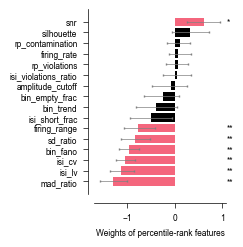

In [35]:
%%time

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig5g", exist_ok=True)
plt.savefig("figures/8_source_data/fig5g/fig5g.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig5g/fig5g.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 15.4 ms, sys: 553 µs, total: 16 ms
Wall time: 15.7 ms


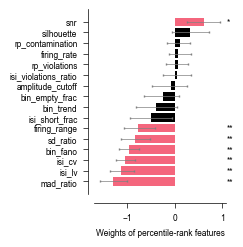

In [36]:
%%time

df = pd.read_excel("figures/8_source_data/fig5g/fig5g.xlsx")
fig, ax = plot_source_data(df)

## Experiment: log-transformed features

* features with a long-tailed distribution (firing rate, firing range, sd ratio, snr, mad ratio) are log-transformed before training and testing the paper's model (paper Methods: "Log-transforming ... did not improve performance")
* the model is the paper's model: fractional logistic regression on the 10 quality metrics (raw features), cross-validated as in the paper with 100 random 75% train / 25% test splits
* median and 95% confidence interval of the precision and recall over the splits; nothing is plotted

In [37]:
%%time

# log-transform the features with a long-tailed distribution
dataset_log = data["dataset"].copy()
for feature in ["firing_rate", "firing_range", "sd_ratio", "snr", "mad_ratio"]:
    dataset_log[feature] = np.log(dataset_log[feature].values)
    assert np.isfinite(dataset_log[feature]).all(), f"{feature} log-transform is not finite"  # unit-test

# paper's model: fractional logistic regression on the 10 quality metrics
paper_model = spikecurate.FractionalLogisticClassifier(data["predictors"])

# train & evaluate w/ cross-validation: raw features and log-transformed features
for name, d in [("raw features", data["dataset"]), ("log-transformed features", dataset_log)]:
    stats_ = paper_model.crossval_evaluate(d, seeds=model_prms["seeds"], scale_data=model_prms["scale_data"])["metric_stats"]
    print(f"{name}: precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), "
          f"recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

raw features: precision median 0.920 (95% CI 0.017), recall median 0.591 (95% CI 0.025)
log-transformed features: precision median 0.920 (95% CI 0.015), recall median 0.591 (95% CI 0.024)
CPU times: user 2.26 s, sys: 7.23 ms, total: 2.26 s
Wall time: 2.26 s
